<a href="https://colab.research.google.com/github/Manvi2404/product-recommendation-system/blob/main/03_model_building.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Fit models

In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import utils
train=pd.read_csv('data/train.csv'); test=pd.read_csv('data/test.csv'); names=utils.load_items()
M=utils.build_matrix(train,log=True); print('matrix',M.shape)

matrix (2000, 800)


In [4]:
pop=utils.PopularityBaseline().fit(M); cf=utils.ItemBasedCF().fit(M); svd=utils.SVDRecommender().fit(M,n_components=30)
print('fitted')

fitted


2. Ranking @10 (relevant = held-out products)

In [5]:
rows=[]
for n,m in [('Popularity',pop),('Item-CF',cf),('SVD',svd)]:
    r=utils.precision_recall_at_k(m,M,test,k=10)
    rows.append({'model':n,'precision@k':r['precision@k'],'recall@k':r['recall@k'],'n_users':r['n_users_evaluated']})
rank_df=pd.DataFrame(rows); rank_df

,model,precision@k,recall@k,n_users
0,Popularity,0.0698,0.0490,2000
1,Item-CF,0.1599,0.1273,2000
2,SVD,0.1964,0.1536,2000


3. Ranking metrics chart

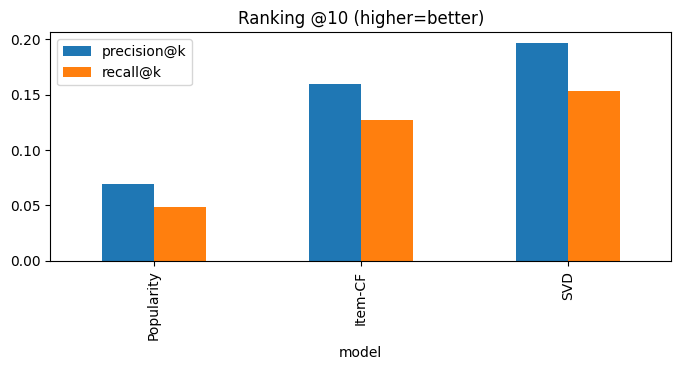

In [6]:
fig,ax=plt.subplots(figsize=(7,3.8))
rank_df.set_index('model')[['precision@k','recall@k']].plot(kind='bar',ax=ax); ax.set_title('Ranking @10 (higher=better)')
plt.tight_layout(); plt.show()

4. Example recommendations (SVD)

In [7]:
uid=M.index[0]
print('recommendations for customer',uid,'\n')
utils.recommend(svd,M,uid,items_lookup=names,n=10)

recommendations for customer 12347.0 



,item,name,score
0,21212,PACK OF 72 RETROSPOT CAKE CASES,1.339
1,22629,SPACEBOY LUNCH BOX,1.241
2,23245,SET OF 3 REGENCY CAKE TINS,1.085
3,22197,POPCORN HOLDER,1.079
4,22730,ALARM CLOCK BAKELIKE IVORY,1.062
5,22630,DOLLY GIRL LUNCH BOX,1.058
6,22551,PLASTERS IN TIN SPACEBOY,0.962
7,47566,PARTY BUNTING,0.860
8,84991,60 TEATIME FAIRY CAKE CASES,0.815
9,21731,RED TOADSTOOL LED NIGHT LIGHT,0.789


5. Summary & takeaways
SVD wins on this implicit dataset — Precision@10 0.194, Recall@10 0.148, ahead of Item-CF (0.158 / 0.125) and far ahead of popularity (0.070 / 0.048).
Contrast with the Music project (also implicit) where Item-CF won: there is no universal winner. With denser per-customer baskets and only 800 products, the low-rank factorization captures cross-category co-purchase structure better than raw item similarity.
Personalisation roughly triples the popularity baseline on Precision@10 — recommending best-sellers to everyone is a weak strategy even in retail.
No RMSE for implicit purchase data — only held-out interactions to rank.
Takeaway across the two implicit and three explicit recommenders: always benchmark item-CF and matrix factorization against a popularity baseline — which one wins depends on the feedback type, density, and catalog size, so measure rather than assume.
